                       Model  Accuracy  Precision (Malignant)  Recall / Sensitivity  F1-Score  ROC-AUC Score  False Negatives (FN)  False Positives (FP)
Baseline Logistic Regression  0.964912               0.975000              0.928571  0.951220       0.996032                     3                     1
Weighted Logistic Regression  0.973684               0.975610              0.952381  0.963855       0.995370                     2                     1
    Decision Tree Classifier  0.929825               0.904762              0.904762  0.904762       0.924603                     4                     4


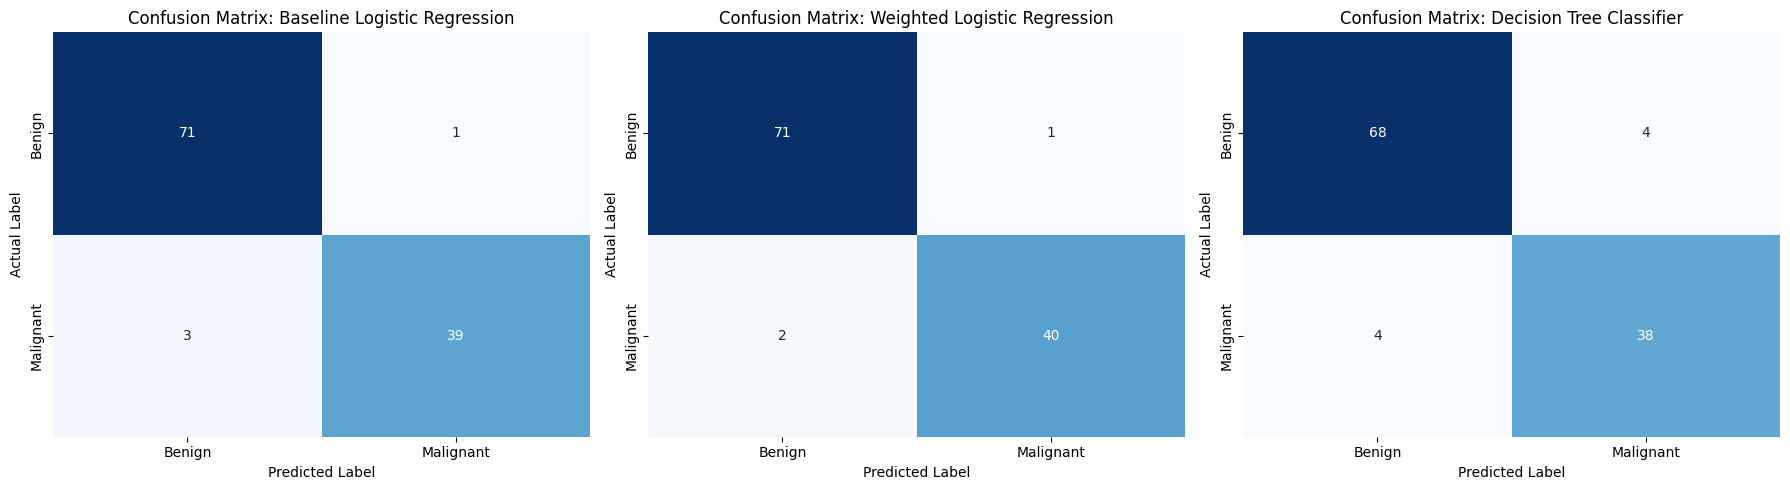

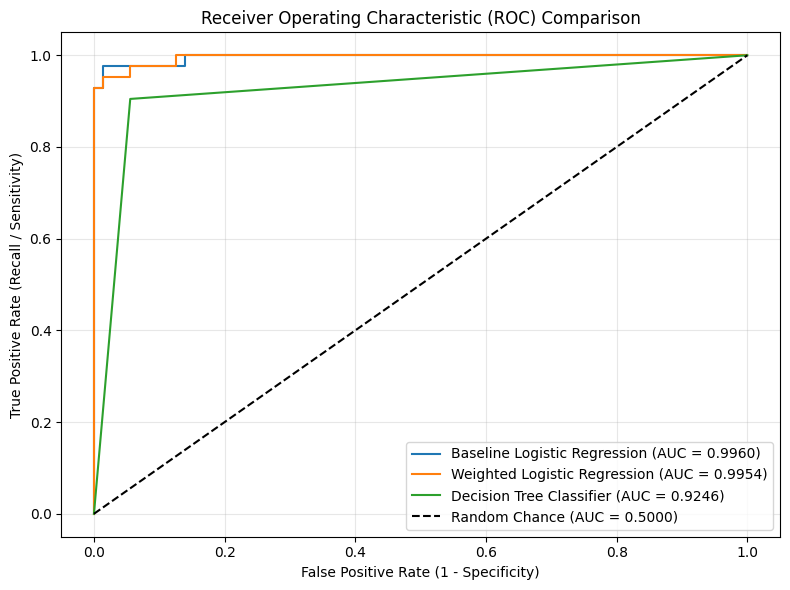

In [2]:
# Step 1: Import Required Libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# Step 2: Load and Prepare Dataset
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="Target")

# Target encoding in scikit-learn load_breast_cancer:
# 0 = Malignant (positive class of primary clinical concern)
# 1 = Benign
# Mapping to binary indicator where Malignant = 1 for clinical clarity:
y_clinical = (y == 0).astype(int)

# Step 3: Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_clinical, test_size=0.2, random_state=42, stratify=y_clinical
)

# Step 4: Feature Scaling (Prevents Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 5: Baseline Logistic Regression Model
baseline_lr = LogisticRegression(max_iter=1000, random_state=42)
baseline_lr.fit(X_train_scaled, y_train)

y_pred_base = baseline_lr.predict(X_test_scaled)
y_prob_base = baseline_lr.predict_proba(X_test_scaled)[:, 1]

# Step 6: Cost-Sensitive Logistic Regression (Class-Weighted)
weighted_lr = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=42
)
weighted_lr.fit(X_train_scaled, y_train)

y_pred_weighted = weighted_lr.predict(X_test_scaled)
y_prob_weighted = weighted_lr.predict_proba(X_test_scaled)[:, 1]

# Step 7: Decision Tree Classifier (Baseline Comparison)
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

# Step 8: Comprehensive Model Performance Evaluation
models = {
    "Baseline Logistic Regression": (y_pred_base, y_prob_base),
    "Weighted Logistic Regression": (y_pred_weighted, y_prob_weighted),
    "Decision Tree Classifier": (y_pred_dt, y_prob_dt),
}

comparison_data = []

for name, (pred, prob) in models.items():
  tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
  comparison_data.append({
      "Model": name,
      "Accuracy": (tp + tn) / (tp + tn + fp + fn),
      "Precision (Malignant)": precision_score(y_test, pred),
      "Recall / Sensitivity": recall_score(y_test, pred),
      "F1-Score": f1_score(y_test, pred),
      "ROC-AUC Score": roc_auc_score(y_test, prob),
      "False Negatives (FN)": fn,
      "False Positives (FP)": fp,
  })

results_df = pd.DataFrame(comparison_data)
print(results_df.to_string(index=False))

# Step 9: Visualizations (Confusion Matrices and ROC Curves)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (name, (pred, _)) in zip(axes, models.items()):
  cm = confusion_matrix(y_test, pred)
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      cbar=False,
      ax=ax,
      xticklabels=["Benign", "Malignant"],
      yticklabels=["Benign", "Malignant"],
  )
  ax.set_title(f"Confusion Matrix: {name}")
  ax.set_xlabel("Predicted Label")
  ax.set_ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Multi-model ROC Curve
plt.figure(figsize=(8, 6))
for name, (_, prob) in models.items():
  fpr, tpr, _ = roc_curve(y_test, prob)
  auc_val = roc_auc_score(y_test, prob)
  plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.4f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Chance (AUC = 0.5000)")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Recall / Sensitivity)")
plt.title("Receiver Operating Characteristic (ROC) Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()